#### Aim: To choose a cambered airfoil NACA-abcd. For a given number of points on the airfoil geometry (N), reconstruct a smooth airfoil surface.


###### Using a random number generator to create NACA-abcd Airfoil.

In [77]:
#generating 3 random numbers for the NACA airfoil
import numpy as np

Max_camber = np.random.randint(75)
Max_c_location = np.random.randint(10)
Thickness = np.random.randint(75)

#print(Max_camber,Max_c_location,Thickness)

Max_camber = Max_camber/100
Max_c_location = Max_c_location/10
Thickness = Thickness/100

print(Max_camber,Max_c_location,Thickness)

#For ease of use
m = Max_camber
p = Max_c_location
t = Thickness

0.01 0.2 0.67


In [81]:
# writing a function to plot a Cambered NACA Airfoil
x_axis = np.linspace(0, 1, 201) #creating n points for the x axis
#print(x)

# Corresponding y values for the generated x values.
y_t = 5*t*(0.2969*(x**0.5) - 0.1260*(x) - 0.3516*(x**2) + 0.2843*(x**3) - 0.1036*(x**4)) # y_t is thickness value

# evaluating y values for the x to plot the camber line
y_c = np.where(x <= p, (m/p**2) * (2*p*x - x**2), (m/(1-p)**2) * ((1 - 2*p) + 2*p*x - x**2))
#print(y_c)

# if x <= p:
#     y_c = (m/p) * (2*p*xi - xi**2)
# elif xi >= p:
#     y_c = (m/(1-p)**2) * ((1 - 2*p) + 2*p*xi - xi**2)

In [82]:
# Evaluating x,y values for the upper and lower surfaces.
# So that the increment in y value due to the camber is perpendicular to the surface and not just along the y-axis 
d_yc = np.where(x <= p, (2*m/p**2) * (p - x),(2*m/(1-p)**2) * (p - x) )

Theta = np.arctan(d_yc)

x_u = x - y_t*np.sin(Theta)
y_u = y_c + y_t*np.cos(Theta)
x_l = x + y_t*np.sin(Theta)
y_l = y_c - y_t*np.cos(Theta)
#print(x_u,x_l)

x_l = np.flip(x_l)
y_l = np.flip(y_l)
#print(x_l)
X = np.concatenate([x_u,x_l])
Y = np.concatenate([y_u,y_l])
#print(X,Y)

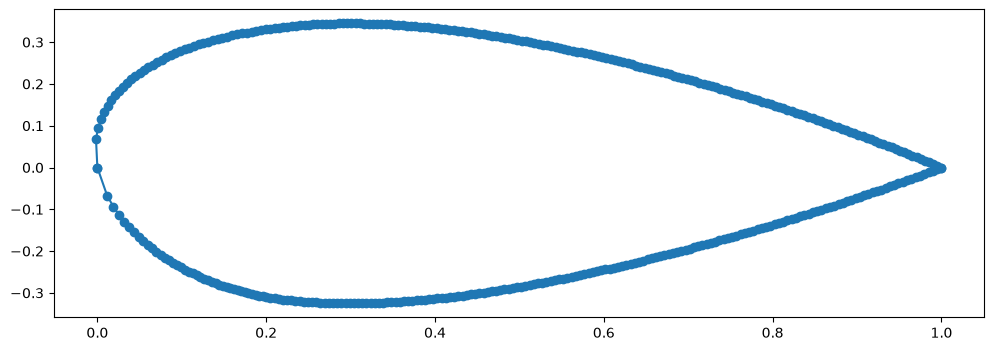

In [83]:

import matplotlib.pyplot as mp
mp.figure(figsize=(12, 4))
mp.plot(X,Y, marker='o')
mp.show()

